# KNN Classifier — Phishing URL Dataset

Huấn luyện mô hình **K-Nearest Neighbors (KNN)** để phân loại URL phishing / legitimate.

**Yêu cầu dữ liệu đầu vào:** `train_processed.csv`, `test_processed.csv` — đã qua bước tiền xử lý
(log1p cho đặc trưng lệch mạnh + StandardScaler cho đặc trưng liên tục, đặc trưng nhị phân giữ nguyên 0/1).

> **Lưu ý quan trọng:** KNN phân loại dựa trên khoảng cách Euclidean/Manhattan giữa các điểm dữ liệu,
> nên **rất nhạy với scale**. Nếu dùng dữ liệu chưa chuẩn hóa, cột có giá trị lớn (vd: `length_url`)
> sẽ lấn át hoàn toàn các cột tỉ lệ nhỏ (vd: `ratio_*`). Vì vậy bắt buộc dùng dữ liệu đã scale.

**Nội dung notebook**
1. Nạp dữ liệu đã xử lý
2. Huấn luyện KNN baseline (k=5)
3. Đánh giá baseline (accuracy, F1, ROC-AUC, confusion matrix)
4. Dò k tối ưu bằng cross-validation + vẽ biểu đồ
5. GridSearchCV tinh chỉnh đầy đủ (k, weights, metric)
6. Đánh giá mô hình tốt nhất trên tập test
7. So sánh baseline vs. sau tuning

In [20]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                              classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42

In [21]:
import os

os.chdir(r"C:\pro_github\final-project-template\project")
print(os.getcwd())

C:\pro_github\final-project-template\project


## 1. Nạp dữ liệu đã xử lý

In [22]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data") / "processed"

train = pd.read_csv(DATA_DIR / "train_processed.csv")
test = pd.read_csv(DATA_DIR / "test_processed.csv")
X_train, y_train = train.drop(columns=['label']), train['label']
X_test, y_test = test.drop(columns=['label']), test['label']

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Tỉ lệ nhãn train:', y_train.mean().round(3), '| test:', y_test.mean().round(3))
display(X_train.head())

Train: (9144, 65) | Test: (2286, 65)
Tỉ lệ nhãn train: 0.5 | test: 0.5


,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,nb_percent,nb_slash,nb_colon,nb_semicolumn,nb_space,nb_www,nb_com,http_in_path,https_token,ratio_digits_url,ratio_digits_host,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,nb_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,nb_extCSS,ratio_extRedirection,ratio_extErrors,login_form,external_favicon,links_in_tags,ratio_intMedia,ratio_extMedia,safe_anchor,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
0,0.427178,-0.460749,1,-0.325167,1.879307,-0.144415,-0.392959,-0.248822,-0.363668,-0.384463,-0.157375,-0.759410,-0.125704,-0.136932,-0.120194,1.096843,-0.353830,-0.111666,0,0.713677,-0.28789,0,0,0,-0.352533,0,0,0,0.953302,0.496047,0.715038,-0.549884,-0.503690,0.194136,-0.366292,0.676563,-0.053984,-0.564674,0.707996,-0.431844,0,0,-0.182303,0.651216,0.933428,-0.717236,-0.587372,-0.655498,-0.431984,0,0,1.156625,1.232911,-0.603102,0.886704,0,1,0,0,-0.005623,1.245409,0.011625,0,1,1.111513
1,1.636288,2.375522,1,1.399998,0.414388,-0.144415,2.447400,3.411298,3.196333,2.327392,-0.157375,0.592637,-0.125704,-0.136932,-0.120194,-0.893538,2.553257,-0.111666,0,1.584253,-0.28789,0,1,0,1.215348,1,0,0,0.953302,1.438665,0.715038,-0.549884,-0.503690,0.194136,0.682216,0.941335,0.388579,0.407453,0.755970,-0.431844,0,0,-0.182303,-0.957008,1.056959,-0.863143,-0.587372,-0.655498,-0.431984,0,0,1.156625,-0.927938,-0.603102,1.620350,0,1,0,0,-0.573523,-0.015353,1.419379,0,1,-1.259115
2,0.793460,-1.359967,0,2.536335,1.062625,-0.144415,-0.392959,-0.248822,-0.363668,-0.384463,-0.157375,1.944683,4.926424,-0.136932,-0.120194,1.096843,2.553257,7.146952,0,-0.614148,-0.28789,0,0,0,1.215348,0,0,1,-0.783150,1.032451,0.972212,-0.549884,0.285863,0.194136,-1.328496,0.736859,-0.656149,-0.775599,0.444807,2.299745,0,0,-0.182303,-1.863140,-1.598971,-0.863143,-0.587372,-0.655498,-0.431984,0,0,-1.249975,-0.927938,-0.603102,-0.947412,0,0,0,0,-0.493755,-1.307747,-1.092261,0,1,-0.073801
3,1.187091,-0.460749,0,-0.325167,1.062625,-0.144415,2.447400,3.411298,3.196333,-0.384463,6.989377,-0.015325,-0.125704,-0.136932,-0.120194,-0.893538,-0.353830,-0.111666,1,0.733681,-0.28789,0,0,0,-0.352533,0,0,0,0.953302,1.861979,-0.005510,-1.543831,0.285863,-0.372738,-0.962683,1.271232,-1.165786,-0.564674,0.229656,-0.431844,1,0,-0.182303,0.184861,-1.455407,2.104290,0.637490,-0.508052,-0.431984,0,1,-1.249975,-0.927938,2.006481,-0.724128,0,0,1,0,0.492033,1.700200,-0.666717,0,1,1.506617
4,-0.221500,-0.783881,1,0.646396,-0.693780,-0.144415,-0.392959,-0.248822,-0.363668,-0.384463,-0.157375,0.592637,-0.125704,-0.136932,-0.120194,-0.893538,-0.353830,-0.111666,1,1.274492,-0.28789,0,0,0,1.215348,0,0,0,1.969062,0.271127,-0.577441,-0.549884,-1.063886,0.596339,-0.366292,0.281541,-0.839845,-0.775599,0.362151,-0.431844,0,0,-0.182303,0.544670,0.907329,-0.686411,-0.587372,2.972405,-0.431984,0,1,0.835745,0.152487,0.701690,1.620350,0,1,0,0,-0.416368,1.003650,0.158481,0,1,-0.073801


## 2. Huấn luyện KNN baseline (k=5)

In [23]:
knn = KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='minkowski', p=2)
knn.fit(X_train, y_train)

pred = knn.predict(X_test)
proba = knn.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, pred)
f1 = f1_score(y_test, pred)
auc = roc_auc_score(y_test, proba)

print(f'Accuracy : {acc:.4f}')
print(f'F1       : {f1:.4f}')
print(f'ROC-AUC  : {auc:.4f}')

Accuracy : 0.9449
F1       : 0.9445
ROC-AUC  : 0.9762


## 3. Đánh giá chi tiết baseline

In [24]:
print(classification_report(y_test, pred, target_names=['legitimate', 'phishing']))

              precision    recall  f1-score   support

  legitimate       0.94      0.95      0.95      1143
    phishing       0.95      0.94      0.94      1143

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286



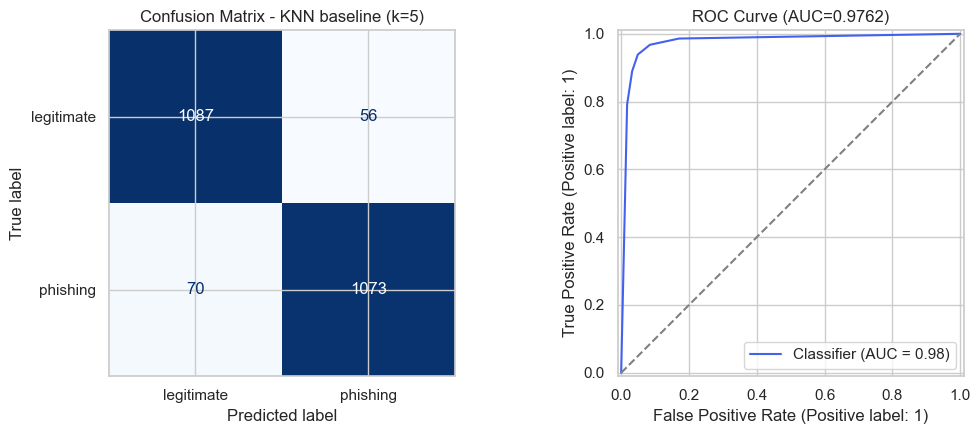

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(cm, display_labels=['legitimate', 'phishing']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix - KNN baseline (k=5)')

RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], curve_kwargs={'color': '#4361ee'})
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title(f'ROC Curve (AUC={auc:.4f})')

plt.tight_layout()
plt.show()

## 4. Dò k tối ưu bằng Cross-Validation

Thử các giá trị k lẻ từ 1 đến 29 (số lẻ để tránh hòa phiếu khi phân loại nhị phân),
đánh giá bằng F1 trung bình qua 5-fold cross-validation trên tập **train**.

In [26]:
k_values = list(range(1, 31, 2))
cv_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1', n_jobs=-1)
    cv_scores.append(scores.mean())
    print(f'k={k:2d}  F1 (cv)={scores.mean():.4f}')

best_k = k_values[int(np.argmax(cv_scores))]
print(f'\nk tốt nhất theo cross-validation: k={best_k} (F1={max(cv_scores):.4f})')

k= 1  F1 (cv)=0.9337
k= 3  F1 (cv)=0.9409
k= 5  F1 (cv)=0.9405
k= 7  F1 (cv)=0.9392
k= 9  F1 (cv)=0.9380
k=11  F1 (cv)=0.9370
k=13  F1 (cv)=0.9354
k=15  F1 (cv)=0.9333
k=17  F1 (cv)=0.9315
k=19  F1 (cv)=0.9315
k=21  F1 (cv)=0.9284
k=23  F1 (cv)=0.9269
k=25  F1 (cv)=0.9256
k=27  F1 (cv)=0.9252
k=29  F1 (cv)=0.9247

k tốt nhất theo cross-validation: k=3 (F1=0.9409)


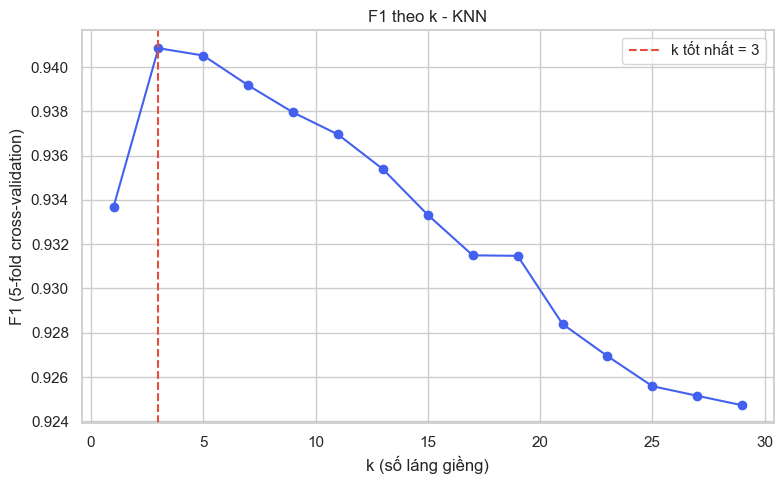

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, cv_scores, marker='o', color='#4361ee')
ax.axvline(best_k, color='#e74c3c', linestyle='--', label=f'k tốt nhất = {best_k}')
ax.set_xlabel('k (số láng giềng)')
ax.set_ylabel('F1 (5-fold cross-validation)')
ax.set_title('F1 theo k - KNN')
ax.legend()
plt.tight_layout()
plt.show()

**Nhận xét:** k nhỏ thường cho F1 cao hơn trên bộ dữ liệu này, và F1 có xu hướng giảm dần khi k tăng
— gợi ý ranh giới giữa 2 lớp khá rõ ràng ở phạm vi lân cận gần.

## 5. GridSearchCV — tinh chỉnh đầy đủ

Dò đồng thời 3 tham số:
- `n_neighbors`: số láng giềng
- `weights`: trọng số đều (`uniform`) hay theo khoảng cách (`distance`, láng giềng gần hơn có trọng số cao hơn)
- `metric`: cách đo khoảng cách (Euclidean, Manhattan, Minkowski)

In [28]:
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21, 25],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski'],
}

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=param_grid, 
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print('Tham số tốt nhất:', grid.best_params_)
print(f'F1 (cross-val): {grid.best_score_:.4f}')

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Tham số tốt nhất: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
F1 (cross-val): 0.9566


In [29]:
results = pd.DataFrame(grid.cv_results_)[['param_n_neighbors', 'param_weights', 'param_metric', 'mean_test_score']]
results = results.sort_values('mean_test_score', ascending=False).reset_index(drop=True)
results.columns = ['k', 'weights', 'metric', 'f1_cv']
display(results.head(10))

,k,weights,metric,f1_cv
0,5,distance,manhattan,0.956630
1,7,distance,manhattan,0.954810
2,3,distance,manhattan,0.954016
3,9,distance,manhattan,0.953773
4,5,uniform,manhattan,0.953150
5,11,distance,manhattan,0.952558
6,3,uniform,manhattan,0.951427
7,15,distance,manhattan,0.951315
8,7,uniform,manhattan,0.950316
9,21,distance,manhattan,0.949709


## 6. Đánh giá mô hình tốt nhất trên tập test

In [30]:
best_knn = grid.best_estimator_
pred_best = best_knn.predict(X_test)
proba_best = best_knn.predict_proba(X_test)[:, 1]

acc_best = accuracy_score(y_test, pred_best)
f1_best = f1_score(y_test, pred_best)
auc_best = roc_auc_score(y_test, proba_best)

print(f'Accuracy : {acc_best:.4f}')
print(f'F1       : {f1_best:.4f}')
print(f'ROC-AUC  : {auc_best:.4f}')
print()
print(classification_report(y_test, pred_best, target_names=['legitimate', 'phishing']))

Accuracy : 0.9563
F1       : 0.9563
ROC-AUC  : 0.9810

              precision    recall  f1-score   support

  legitimate       0.96      0.96      0.96      1143
    phishing       0.96      0.96      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



In [ ]:
# Dự đoán trên tập train và test
y_train_pred = best_knn.predict(X_train)
y_test_pred = best_knn.predict(X_test)

# Tính Accuracy
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

# Tính F1-score
train_f1 = f1_score(y_train, y_train_pred,  average="weighted")
test_f1 = f1_score(y_test, y_test_pred,  average="weighted")

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Train F1      : {train_f1:.4f}")
print(f"Test F1       : {test_f1:.4f}")
print(f"Accuracy gap  : {train_acc - test_acc:.4f}")

Train Accuracy: 1.0000
Test Accuracy : 0.9563
Train F1      : 1.0000
Test F1       : 0.9563
Accuracy gap  : 0.0437


: 

In [35]:
print("Nhãn y_train:", y_train.unique())

Nhãn y_train: [0 1]


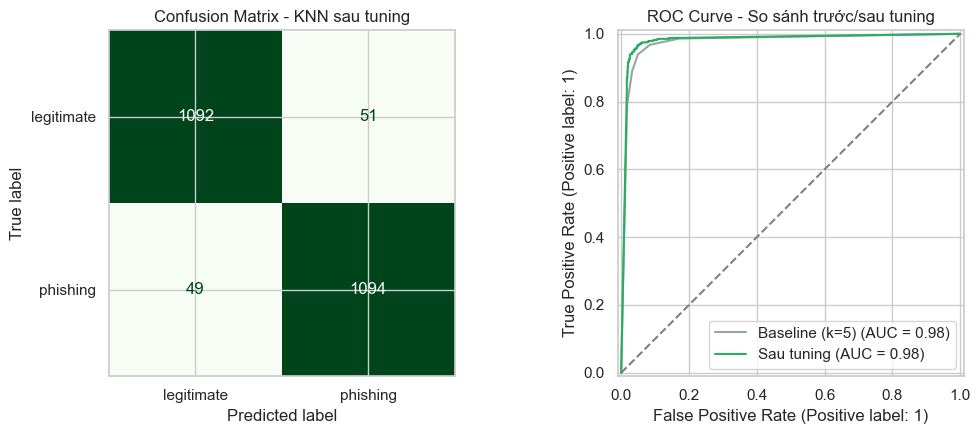

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

cm_best = confusion_matrix(y_test, pred_best)
ConfusionMatrixDisplay(cm_best, display_labels=['legitimate', 'phishing']).plot(
    ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Confusion Matrix - KNN sau tuning')

RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name='Baseline (k=5)', curve_kwargs={'color': '#95a5a6'})
RocCurveDisplay.from_predictions(y_test, proba_best, ax=axes[1], name='Sau tuning', curve_kwargs={'color': '#27ae60'})
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray')
axes[1].set_title('ROC Curve - So sánh trước/sau tuning')

plt.tight_layout()
plt.show()

## 7. So sánh baseline vs. sau tuning

,Baseline (k=5),Sau tuning
Accuracy,0.9449,0.9563
F1,0.9445,0.9563
ROC-AUC,0.9762,0.9810


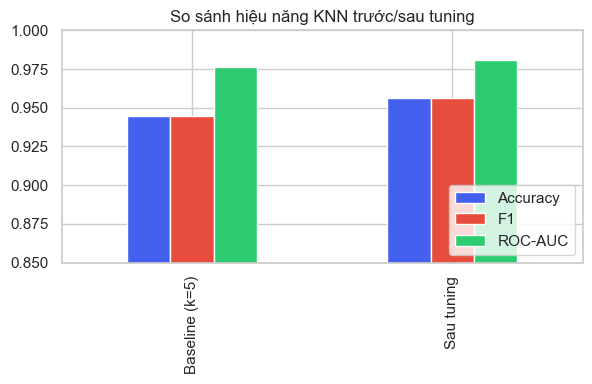

Tham số tốt nhất: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}


In [32]:
compare = pd.DataFrame({
    'Baseline (k=5)': [acc, f1, auc],
    'Sau tuning': [acc_best, f1_best, auc_best],
}, index=['Accuracy', 'F1', 'ROC-AUC'])
display(compare.round(4))

fig, ax = plt.subplots(figsize=(6, 4))
compare.T.plot(kind='bar', ax=ax, color=['#4361ee', '#e74c3c', '#2ecc71'])
ax.set_ylim(0.85, 1.0)
ax.set_title('So sánh hiệu năng KNN trước/sau tuning')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Tham số tốt nhất: {grid.best_params_}")

## Tóm tắt

| Bước | Việc làm |
|---|---|
| Baseline | KNN mặc định (k=5, uniform, Minkowski/Euclidean) |
| Dò k | Cross-validation 5-fold, thử k lẻ 1→29 |
| Tinh chỉnh | GridSearchCV trên k, weights, metric |
| Đánh giá | Accuracy, F1, ROC-AUC, confusion matrix trên tập test |

**Lưu ý triển khai:** vì KNN phải tính khoảng cách tới toàn bộ (hoặc một phần, tùy cấu trúc index) điểm
trong tập train tại thời điểm dự đoán, tốc độ suy luận sẽ chậm dần khi dữ liệu train lớn lên — khác với
các mô hình như Random Forest/Gradient Boosting (học xong thì dự đoán rất nhanh, không phụ thuộc kích
thước tập train nữa).